In [ ]:
!git clone --recursive https://github.com/microsoft/BitNet.git
%cd BitNet
!pip install -q -r requirements.txt
%cd gpu
!pip install -q -r requirements.txt
!pip install -q --upgrade torch torchvision torchaudio


Cloning into 'BitNet'...
remote: Enumerating objects: 432, done.
remote: Total 432 (delta 0), reused 0 (delta 0), pack-reused 432 (from 1)
Receiving objects: 100% (432/432), 8.12 MiB | 5.92 MiB/s, done.
Resolving deltas: 100% (196/196), done.
Submodule '3rdparty/llama.cpp' (https://github.com/Eddie-Wang1120/llama.cpp.git) registered for path '3rdparty/llama.cpp'
Cloning into '/content/BitNet/3rdparty/llama.cpp'...
remote: Enumerating objects: 25639, done.        
remote: Total 25639 (delta 0), reused 0 (delta 0), pack-reused 25639 (from 1)        
Receiving objects: 100% (25639/25639), 59.71 MiB | 16.91 MiB/s, done.
Resolving deltas: 100% (18203/18203), done.
Submodule path '3rdparty/llama.cpp': checked out '1f86f058de0c3f4098dedae2ae8653c335c868a1'
Submodule 'kompute' (https://github.com/nomic-ai/kompute.git) registered for path '3rdparty/llama.cpp/ggml/src/kompute'
Cloning into '/content/BitNet/3rdparty/llama.cpp/ggml/src/kompute'...
remote: Enumerating objects: 9122, done.        
r

In [ ]:
## Restart Runtime Here ##



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import torch
import torchvision
import torchvision.transforms as transforms
import kagglehub
from torch.utils.data import ConcatDataset, DataLoader, Dataset
from torchvision.datasets import ImageFolder
from PIL import Image
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using {device} device")


# Download latest version of ImageNet100
path = kagglehub.dataset_download("ambityga/imagenet100")
print("Path to dataset files:", path)

BATCH_SIZE = 128

from torchvision.transforms import RandAugment
from timm.data.auto_augment import rand_augment_transform

# augmentations
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    rand_augment_transform('rand-m9-mstd0.5', {}),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.25)
])

transform_val = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class MergedImageFolder(Dataset):
    def __init__(self, roots, transform=None):
        all_classes = set()
        for root in roots:
            all_classes.update(os.listdir(root))
        self.classes = sorted(all_classes)
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}

        self.samples = []
        for root in roots:
            for cls in os.listdir(root):
                cls_idx = self.class_to_idx[cls]
                cls_dir = os.path.join(root, cls)
                for img in os.listdir(cls_dir):
                    self.samples.append((os.path.join(cls_dir, img), cls_idx))

        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

# training dataset with augmentation
train_dataset = MergedImageFolder([
    f'{path}/train.X1',
    f'{path}/train.X2',
    f'{path}/train.X3',
    f'{path}/train.X4'
], transform=transform_train)

# test dataset with val transforms (no augmentation)
test_dataset_no_aug = MergedImageFolder([
    f'{path}/train.X1',
    f'{path}/train.X2',
    f'{path}/train.X3',
    f'{path}/train.X4'
], transform=transform_val)

# stratified split
targets = [sample[1] for sample in train_dataset.samples]
train_indices, test_indices = train_test_split(
    range(len(train_dataset)),
    test_size=5000,
    stratify=targets,
    random_state=42
)

from torch.utils.data import Subset
train_subset = Subset(train_dataset, train_indices)
test_subset = Subset(test_dataset_no_aug, test_indices)


val_dataset = ImageFolder(f'{path}/val.X', transform=transform_val)


train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=os.cpu_count(), pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=os.cpu_count(), pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=os.cpu_count(), pin_memory=True, persistent_workers=True)

print(f"Training samples: {len(train_subset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_subset)}")

using cuda device
Using Colab cache for faster access to the 'imagenet100' dataset.
Path to dataset files: /kaggle/input/imagenet100
Training samples: 125000
Validation samples: 5000
Test samples: 5000


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

def RMSNorm(x, eps=1e-5):
    return x / torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + eps)

def activation_quant(x):
  scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
  y = (x * scale).round().clamp_(-128,127) / scale
  return y

def weight_quant(w):
  scale = 1.0 / w.abs().mean().clamp_(min=1e-5)
  u = (w * scale).round().clamp_(-1,1) / scale
  return u



class BitLinear(nn.Linear):
    def forward(self, x):
        w = self.weight
        x_quant = x + (activation_quant(x) - x).detach()
        w_quant = w + (weight_quant(w) - w).detach()
        y = F.linear(x_quant, w_quant, self.bias)
        return y


In [ ]:
# Apply these changes to the .cu file:


cu_file_path = '/content/BitNet/gpu/bitnet_kernels/bitnet_kernels.cu'

new_entries = """    else if (M == 1 && N == 576 && K == 192){
        ladder_int8xint2_kernel<1, 576, 192, 1, 8, 16><<<dim3(36, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }
    else if (M == 1 && N == 192 && K == 192){
        ladder_int8xint2_kernel<1, 192, 192, 1, 8, 16><<<dim3(12, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }
    else if (M == 1 && N == 768 && K == 192){
        ladder_int8xint2_kernel<1, 768, 192, 1, 8, 16><<<dim3(48, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }
    else if (M == 1 && N == 192 && K == 768){
        ladder_int8xint2_kernel<1, 192, 768, 1, 8, 16><<<dim3(12, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }
    else if (M == 1 && N == 112 && K == 192){
        ladder_int8xint2_kernel<1, 112, 192, 1, 8, 16><<<dim3(7, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }"""

with open(cu_file_path, 'r') as f:
    content = f.read()

old_else = '    else{\n        std::cout << "required ladder gemm kernel'
new_content = content.replace(old_else, new_entries + '\n' + old_else)

with open(cu_file_path, 'w') as f:
    f.write(new_content)



%cd /content/BitNet/gpu/bitnet_kernels
!bash compile.sh

/content/BitNet/gpu/bitnet_kernels


In [ ]:
import ctypes
bitnet_lib = ctypes.CDLL('/content/BitNet/gpu/bitnet_kernels/libbitnet.so')


# invokes the cuda kernel
def bitnet_int8xint2_linear(input0, input1, s, ws):
    out_shape = list(input0.shape)
    out_shape[-1] = input1.shape[0]

    N = input1.shape[0]
    K = input1.shape[1] * 4

    original_shape = input0.shape
    if input0.dim() == 3:
        input0 = input0.reshape(-1, input0.shape[-1])
        s = s.reshape(-1, 1)

    M = input0.shape[0]

    ret = torch.zeros(M, N, dtype=torch.bfloat16, device=input0.device)
    s = s.to(torch.bfloat16).contiguous()


    streams = [torch.cuda.Stream() for _ in range(M)]

    for i in range(M):
        with torch.cuda.stream(streams[i]):
            row = input0[i:i+1].contiguous()
            scale = s[i:i+1].contiguous()
            bitnet_lib.bitlinear_int8xint2(
                *[ctypes.c_void_p(row.data_ptr()),
                  ctypes.c_void_p(input1.data_ptr()),
                  ctypes.c_void_p(ret[i:i+1].data_ptr()),
                  ctypes.c_void_p(scale.data_ptr()),
                  ctypes.c_void_p(ws.data_ptr()),
                  ctypes.c_int(1),
                  ctypes.c_int(N),
                  ctypes.c_int(K),
                  ctypes.c_void_p(streams[i].cuda_stream)]
            )
        streams[i].synchronize()


    torch.cuda.synchronize()

    ret = ret.reshape(*out_shape)
    return ret




class BitLinearKernel(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.weight = nn.Parameter(torch.zeros(out_features, in_features//4, dtype=torch.int8), requires_grad=False)
        self.weight_scale = nn.Parameter(torch.zeros(4, dtype=torch.bfloat16), requires_grad=False)
        if bias:
            self.bias = nn.Parameter(torch.zeros(out_features), requires_grad=False)
        else:
            self.bias = None

    def quant_input(self, input):
        s = 127 / input.abs().max(dim=-1, keepdim=True).values.clamp(min=1e-5)
        return (input * s).round().clamp(-128, 127).to(torch.int8), s

    def forward(self, input):
        input, s = self.quant_input(input)
        out = bitnet_int8xint2_linear(input, self.weight, s, self.weight_scale)
        if self.bias is not None:
            out = out + self.bias.to(out.dtype)
        return out

In [ ]:

import timm
import types


# the only real change is the splicing at the end which ignores the 12 added neurons
def new_forward(self, x, attn_mask=None, is_causal=False):
    x = self.forward_features(x, attn_mask=attn_mask, is_causal=is_causal)
    x = self.forward_head(x)
    return x[:, :100]


In [ ]:
#Train the baseline model

from tqdm import tqdm
import time
import numpy as np
import random

NUM_RUNS = 3
NUM_EPOCHS = 15
LEARNING_RATE = 1e-4

all_histories = []
run_times_baseline = []
run_final_accs_baseline = []

for run in range(NUM_RUNS):
    torch.manual_seed(run)
    torch.cuda.manual_seed(run)

    # reinitialize model from pretrained weights each run
    model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    model.head = nn.Linear(192, 112, bias=True)
    model.forward = types.MethodType(new_forward, model)
    model = model.to(device)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = model(batch)
            optimizer.zero_grad()
            loss = loss_fn(output, labels)
            train_loss += loss.detach()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = model(batch)
                loss = loss_fn(output, labels)
                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'Run {run+1} Epoch {i+1}/{NUM_EPOCHS}: Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}')

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    run_times_baseline.append(run_time)
    run_final_accs_baseline.append(val_acc)
    all_histories.append(history)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_time:.2f}s")
    print(f"  Final val accuracy: {val_acc:.4f}")

    torch.save(model.state_dict(), f'/content/baseline_run{run}.pth')

print(f"\n{'='*40}")
print(f"BASELINE TRAINING SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time: {np.mean(run_times_baseline):.2f}s ± {np.std(run_times_baseline):.2f}s")
print(f"Final val accuracy: {np.mean(run_final_accs_baseline):.4f} ± {np.std(run_final_accs_baseline):.4f}")



Run 1/3 Epoch 1/15 Validation: 100%|██████████| 40/40 [00:06<00:00,  6.48it/s]


Run 1 Epoch 1/15: Train Loss=4.3240, Train Acc=0.0487, Val Loss=3.9082, Val Acc=0.1076


Run 1/3 Epoch 2/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.80it/s]


Run 1 Epoch 2/15: Train Loss=4.0319, Train Acc=0.0904, Val Loss=3.6178, Val Acc=0.1550


Run 1/3 Epoch 3/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.06it/s]


Run 1 Epoch 3/15: Train Loss=3.8571, Train Acc=0.1173, Val Loss=3.4124, Val Acc=0.2008


... (80 outputs left out)

Run 3/3 Epoch 14/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.77it/s]


Run 3 Epoch 14/15: Train Loss=3.0785, Train Acc=0.2600, Val Loss=2.4925, Val Acc=0.3800


Run 3/3 Epoch 15/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.04it/s]


Run 3 Epoch 15/15: Train Loss=3.0326, Train Acc=0.2697, Val Loss=2.4566, Val Acc=0.3742

Run 3 results:
  Time: 3317.46s
  Final val accuracy: 0.3742

BASELINE TRAINING SUMMARY (3 runs)
Training time: 3320.01s ± 7.39s
Final val accuracy: 0.3799 ± 0.0047


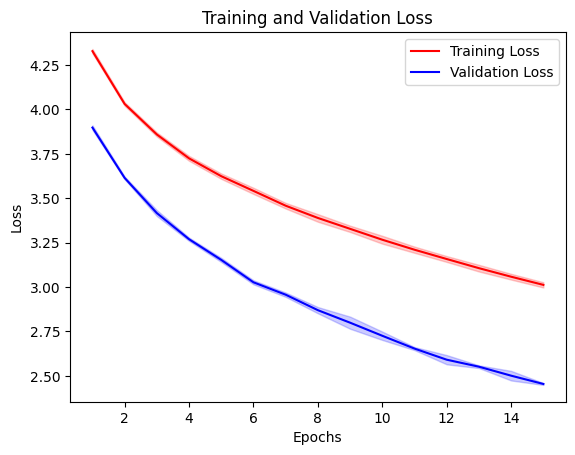

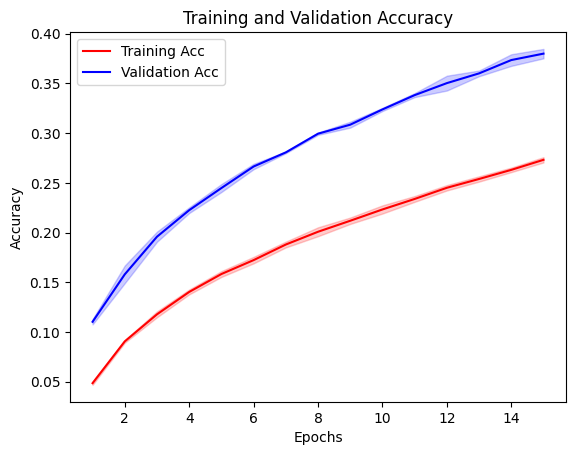

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/vit_baseline_loss_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/vit_baseline_acc_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
import shutil
shutil.copy('/content/vit_baseline_loss_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_GEMV/vit_baseline_loss_plot.pdf')
shutil.copy('/content/vit_baseline_acc_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_GEMV/vit_baseline_accuracy_plot.pdf')

'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_GEMV/vit_baseline_accuracy_plot.pdf'

In [ ]:
def warmup_gpu(model, dataloader, num_batches=5):
    model.eval()
    with torch.no_grad():
        for i, (batch, _) in enumerate(dataloader):
            if i >= num_batches:
                break
            batch = batch.to(device)
            _ = model(batch)
    torch.cuda.synchronize() # ensures that warmup completes before training and timing begins.
    print(f"GPU warmup complete ({num_batches} batches)")

In [ ]:
# baseline inference
NUM_EVAL_RUNS = 3

eval_times_baseline = []
eval_losses_baseline = []
eval_accs_baseline = []
eval_latencies_baseline = []
eval_throughputs_baseline = []

for run in range(NUM_EVAL_RUNS):
    baseline_model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    baseline_model.head = nn.Linear(192, 112, bias=True)
    baseline_model.forward = types.MethodType(new_forward, baseline_model)
    baseline_model.load_state_dict(torch.load(f'/content/baseline_run{run}.pth'))
    baseline_model = baseline_model.to(device)
    baseline_model.eval()

    if run == 0:
        warmup_gpu(baseline_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Baseline Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = baseline_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_baseline.append(run_time)
    eval_losses_baseline.append(test_loss / len(test_loader))
    eval_accs_baseline.append(test_correct_predictions / test_total)
    eval_latencies_baseline.append(run_time / len(test_loader) * 1000)
    eval_throughputs_baseline.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_baseline[-1]:.4f}, Accuracy={eval_accs_baseline[-1]:.4f}, Latency={eval_latencies_baseline[-1]:.2f}ms, Throughput={eval_throughputs_baseline[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BASELINE INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_baseline):.2f}s ± {np.std(eval_times_baseline):.2f}s")
print(f"Loss:       {np.mean(eval_losses_baseline):.4f} ± {np.std(eval_losses_baseline):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_baseline):.4f} ± {np.std(eval_accs_baseline):.4f}")
print(f"Latency:    {np.mean(eval_latencies_baseline):.2f}ms ± {np.std(eval_latencies_baseline):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_baseline):.2f} ± {np.std(eval_throughputs_baseline):.2f} samples/s")

GPU warmup complete (5 batches)


Baseline Testing run 1/3: 100%|██████████| 40/40 [00:08<00:00,  4.67it/s]


Run 1: Time=8.57s, Loss=2.2677, Accuracy=0.4266, Latency=214.25ms, Throughput=583.44 samples/s


Baseline Testing run 2/3: 100%|██████████| 40/40 [00:05<00:00,  6.88it/s]


Run 2: Time=5.81s, Loss=2.2760, Accuracy=0.4212, Latency=145.30ms, Throughput=860.31 samples/s


Baseline Testing run 3/3: 100%|██████████| 40/40 [00:05<00:00,  6.74it/s]

Run 3: Time=5.94s, Loss=2.2801, Accuracy=0.4224, Latency=148.38ms, Throughput=842.41 samples/s

BASELINE INFERENCE SUMMARY (3 runs)
Time:       6.77s ± 1.27s
Loss:       2.2746 ± 0.0052
Accuracy:   0.4234 ± 0.0023
Latency:    169.31ms ± 31.80ms
Throughput: 762.05 ± 126.51 samples/s


In [ ]:
#Train the bitlinear model

from tqdm import tqdm
import time

# NUM_EPOCHS = 3
# NUM_RUNS = 1
# LEARNING_RATE = 1e-4

all_histories = []
run_times_bitlinear = []
run_final_accs_bitlinear = []

for run in range(NUM_RUNS):
    torch.manual_seed(run)
    torch.cuda.manual_seed(run)

    # reinitialize model from pretrained weights each run
    model = timm.create_model('vit_tiny_patch16_224', pretrained=False)

    for block in model.blocks:
        block.attn.qkv = BitLinear(192, 576, bias=False)
        block.attn.proj = BitLinear(192, 192, bias=False)
        block.mlp.fc1 = BitLinear(192, 768, bias=False)
        block.mlp.fc2 = BitLinear(768, 192, bias=False)


    model.head = BitLinear(192, 112, bias=True)
    model.forward = types.MethodType(new_forward, model)
    model = model.to(device)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = model(batch)
            optimizer.zero_grad()
            loss = loss_fn(output, labels)
            train_loss += loss.detach()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Run {run+1}/{NUM_RUNS} Epoch {i+1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = model(batch)
                loss = loss_fn(output, labels)
                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'Run {run+1} Epoch {i+1}/{NUM_EPOCHS}: Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}')

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    run_times_bitlinear.append(run_time)
    run_final_accs_bitlinear.append(val_acc)
    all_histories.append(history)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_time:.2f}s")
    print(f"  Final val accuracy: {val_acc:.4f}")

    torch.save(model.state_dict(), f'/content/unquantized_run{run}.pth')

print(f"\n{'='*40}")
print(f"BITLINEAR TRAINING SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time: {np.mean(run_times_bitlinear):.2f}s ± {np.std(run_times_bitlinear):.2f}s")
print(f"Final val accuracy: {np.mean(run_final_accs_bitlinear):.4f} ± {np.std(run_final_accs_bitlinear):.4f}")





Run 1/3 Epoch 1/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.89it/s]


Run 1 Epoch 1/15: Train Loss=4.3761, Train Acc=0.0431, Val Loss=4.0168, Val Acc=0.0964


Run 1/3 Epoch 2/15 Validation: 100%|██████████| 40/40 [00:06<00:00,  6.66it/s]


Run 1 Epoch 2/15: Train Loss=4.1311, Train Acc=0.0784, Val Loss=3.7724, Val Acc=0.1434


Run 1/3 Epoch 3/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  7.09it/s]


Run 1 Epoch 3/15: Train Loss=3.9892, Train Acc=0.0981, Val Loss=3.6494, Val Acc=0.1618


... (80 outputs left out)

Run 3/3 Epoch 14/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.85it/s]


Run 3 Epoch 14/15: Train Loss=3.2750, Train Acc=0.2217, Val Loss=2.7572, Val Acc=0.3160


Run 3/3 Epoch 15/15 Validation: 100%|██████████| 40/40 [00:05<00:00,  6.74it/s]

Run 3 Epoch 15/15: Train Loss=3.2398, Train Acc=0.2292, Val Loss=2.6803, Val Acc=0.3342

Run 3 results:
  Time: 3374.54s
  Final val accuracy: 0.3342

BITLINEAR TRAINING SUMMARY (3 runs)
Training time: 3368.24s ± 9.45s
Final val accuracy: 0.3297 ± 0.0032


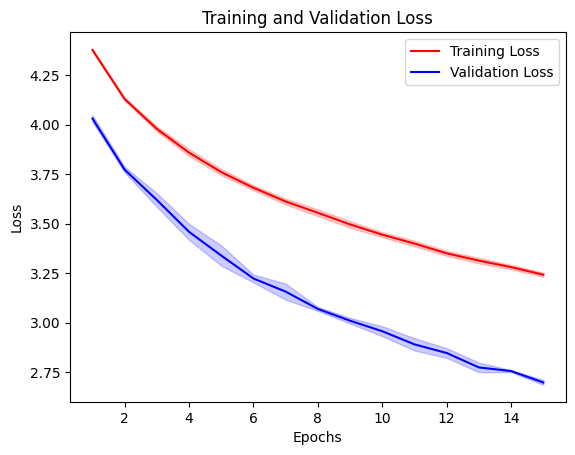

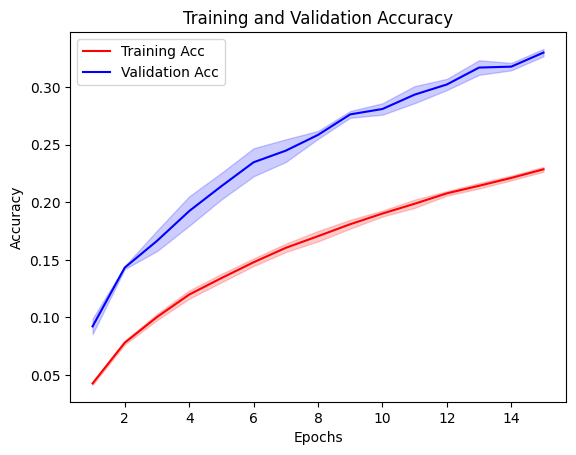

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig('/content/vit_bitlinear_loss_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('/content/vit_bitlinear_acc_plot.pdf',bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
shutil.copy('/content/vit_bitlinear_loss_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_GEMV/vit_bitlinear_loss_plot.pdf')
shutil.copy('/content/vit_bitlinear_acc_plot.pdf', '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_GEMV/vit_bitlinear_accuracy_plot.pdf')

'/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/plots/ViT_GEMV/vit_bitlinear_accuracy_plot.pdf'

In [ ]:
# BitLinear inference
eval_times_bitlinear = []
eval_losses_bitlinear = []
eval_accs_bitlinear = []
eval_latencies_bitlinear = []
eval_throughputs_bitlinear = []

for run in range(NUM_EVAL_RUNS):
    bitlinear_model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    bitlinear_model.head = BitLinear(192, 112, bias=True)
    for block in bitlinear_model.blocks:
        block.attn.qkv = BitLinear(192, 576, bias=False)
        block.attn.proj = BitLinear(192, 192, bias=False)
        block.mlp.fc1 = BitLinear(192, 768, bias=False)
        block.mlp.fc2 = BitLinear(768, 192, bias=False)
    bitlinear_model.forward = types.MethodType(new_forward, bitlinear_model)
    bitlinear_model.load_state_dict(torch.load(f'/content/unquantized_run{run}.pth'),strict=False)
    bitlinear_model = bitlinear_model.to(device)
    bitlinear_model.eval()

    if run == 0:
        warmup_gpu(bitlinear_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'BitLinear Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = bitlinear_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_bitlinear.append(run_time)
    eval_losses_bitlinear.append(test_loss / len(test_loader))
    eval_accs_bitlinear.append(test_correct_predictions / test_total)
    eval_latencies_bitlinear.append(run_time / len(test_loader) * 1000)
    eval_throughputs_bitlinear.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_bitlinear[-1]:.4f}, Accuracy={eval_accs_bitlinear[-1]:.4f}, Latency={eval_latencies_bitlinear[-1]:.2f}ms, Throughput={eval_throughputs_bitlinear[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BITLINEAR INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_bitlinear):.2f}s ± {np.std(eval_times_bitlinear):.2f}s")
print(f"Loss:       {np.mean(eval_losses_bitlinear):.4f} ± {np.std(eval_losses_bitlinear):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_bitlinear):.4f} ± {np.std(eval_accs_bitlinear):.4f}")
print(f"Latency:    {np.mean(eval_latencies_bitlinear):.2f}ms ± {np.std(eval_latencies_bitlinear):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_bitlinear):.2f} ± {np.std(eval_throughputs_bitlinear):.2f} samples/s")

GPU warmup complete (5 batches)


BitLinear Testing run 1/3: 100%|██████████| 40/40 [00:08<00:00,  4.74it/s]


Run 1: Time=8.44s, Loss=2.5282, Accuracy=0.3748, Latency=210.94ms, Throughput=592.58 samples/s


BitLinear Testing run 2/3: 100%|██████████| 40/40 [00:05<00:00,  6.83it/s]


Run 2: Time=5.86s, Loss=2.5455, Accuracy=0.3674, Latency=146.52ms, Throughput=853.15 samples/s


BitLinear Testing run 3/3: 100%|██████████| 40/40 [00:06<00:00,  6.43it/s]

Run 3: Time=6.22s, Loss=2.4996, Accuracy=0.3762, Latency=155.52ms, Throughput=803.77 samples/s

BITLINEAR INFERENCE SUMMARY (3 runs)
Time:       6.84s ± 1.14s
Loss:       2.5244 ± 0.0190
Accuracy:   0.3728 ± 0.0039
Latency:    170.99ms ± 28.49ms
Throughput: 749.83 ± 113.01 samples/s


In [ ]:
%cd /content/BitNet/gpu

/content/BitNet/gpu


In [ ]:
# Quantization


from pack_weight import convert_weight_int8_to_int2

def quant_to_8_bit(weight):
    s = 1.0 / weight.abs().mean().clamp_(min=1e-5)
    new_weight = (weight * s).round().clamp(-1, 1).to(torch.int8)
    new_scale = (1.0 / s).to(torch.bfloat16)
    return new_weight, new_scale.reshape(1)

def convert_8_bit_to_2_bit(weight):
    return convert_weight_int8_to_int2(weight)

zero = torch.zeros(1).to(torch.bfloat16)

for run in range(NUM_RUNS):
    checkpoint = torch.load(f'/content/unquantized_run{run}.pth', map_location="cpu", mmap=True)
    checkpoint = {k.replace('_orig_mod.', ''): v for k, v in checkpoint.items()}

    int2_res = {}

    for key, value in checkpoint.items():
        if 'weight' in key and value.dim() == 2:
            weight, scale = quant_to_8_bit(value)
            scale = torch.cat([scale, zero, zero, zero], dim=0)
            int2_res[key] = convert_8_bit_to_2_bit(weight)
            int2_res[key.replace('weight', 'weight_scale')] = scale
        else:
            int2_res[key] = value.clone()

    torch.save(int2_res, f'/content/quantized_run{run}.pth')
    print(f"Run {run}: weights quantized and saved to quantized_run{run}.pth")

print("All runs quantized successfully")

Run 0: weights quantized and saved to quantized_run0.pth
Run 1: weights quantized and saved to quantized_run1.pth
Run 2: weights quantized and saved to quantized_run2.pth
All runs quantized successfully


In [ ]:
import shutil
import os

save_dir = '/content/drive/MyDrive/GMU_MS_CS/MS_Thesis/checkpoints/ViT/GEMV'
os.makedirs(save_dir, exist_ok=True)

for run in range(NUM_RUNS):
    for name in ['unquantized', 'quantized', 'baseline']:
        src = f'/content/{name}_run{run}.pth'
        if os.path.exists(src):
            shutil.copy(src, f'{save_dir}/{name}_run{run}.pth')
            print(f"Saved {name}_run{run}.pth")
        else:
            print(f"{name}_run{run}.pth not found")


print("\nAll checkpoints saved to Google Drive")

Saved unquantized_run0.pth
Saved quantized_run0.pth
Saved baseline_run0.pth
Saved unquantized_run1.pth
Saved quantized_run1.pth
Saved baseline_run1.pth
Saved unquantized_run2.pth
Saved quantized_run2.pth
Saved baseline_run2.pth

All checkpoints saved to Google Drive


In [ ]:
# inference kernel
eval_times_kernel = []
eval_losses_kernel = []
eval_accs_kernel = []
eval_latencies_kernel = []
eval_throughputs_kernel = []

loss_fn = torch.nn.CrossEntropyLoss()

for run in range(NUM_EVAL_RUNS):
    inference_model = timm.create_model('vit_tiny_patch16_224', pretrained=False)
    inference_model.head = BitLinearKernel(192, 112, bias=False)
    for block in inference_model.blocks:
        block.attn.qkv = BitLinearKernel(192, 576, bias=False)
        block.attn.proj = BitLinearKernel(192, 192, bias=False)
        block.mlp.fc1 = BitLinearKernel(192, 768, bias=False)
        block.mlp.fc2 = BitLinearKernel(768, 192, bias=False)
    inference_model.forward = types.MethodType(new_forward, inference_model)
    inference_model = inference_model.to(device)
    inference_model.load_state_dict(torch.load(f'/content/quantized_run{run}.pth'), strict=False)
    inference_model.eval()

    if run == 0:
        warmup_gpu(inference_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Kernel Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = inference_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_kernel.append(run_time)
    eval_losses_kernel.append(test_loss / len(test_loader))
    eval_accs_kernel.append(test_correct_predictions / test_total)
    eval_latencies_kernel.append(run_time / len(test_loader) * 1000)
    eval_throughputs_kernel.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_kernel[-1]:.4f}, Accuracy={eval_accs_kernel[-1]:.4f}, Latency={eval_latencies_kernel[-1]:.2f}ms, Throughput={eval_throughputs_kernel[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"INFERENCE KERNEL SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_kernel):.2f}s ± {np.std(eval_times_kernel):.2f}s")
print(f"Loss:       {np.mean(eval_losses_kernel):.4f} ± {np.std(eval_losses_kernel):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_kernel):.4f} ± {np.std(eval_accs_kernel):.4f}")
print(f"Latency:    {np.mean(eval_latencies_kernel):.2f}ms ± {np.std(eval_latencies_kernel):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_kernel):.2f} ± {np.std(eval_throughputs_kernel):.2f} samples/s")

GPU warmup complete (5 batches)


Kernel Testing run 1/3: 100%|██████████| 40/40 [37:41<00:00, 56.54s/it]


Run 1: Time=2261.60s, Loss=4.1422, Accuracy=0.0724, Latency=56539.94ms, Throughput=2.21 samples/s


Kernel Testing run 2/3: 100%|██████████| 40/40 [37:55<00:00, 56.88s/it]


Run 2: Time=2275.02s, Loss=4.2375, Accuracy=0.0686, Latency=56875.62ms, Throughput=2.20 samples/s


Kernel Testing run 3/3: 100%|██████████| 40/40 [37:51<00:00, 56.79s/it]

Run 3: Time=2271.42s, Loss=4.1332, Accuracy=0.0684, Latency=56785.41ms, Throughput=2.20 samples/s

INFERENCE KERNEL SUMMARY (3 runs)
Time:       2269.35s ± 5.67s
Loss:       4.1710 ± 0.0472
Accuracy:   0.0698 ± 0.0018
Latency:    56733.65ms ± 141.84ms
Throughput: 2.20 ± 0.01 samples/s


In [ ]:
# parameter counts, size on disk
def model_stats(model, filepath):
    # parameter count
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # size on disk
    torch.save(model.state_dict(), filepath)
    size_mb = os.path.getsize(filepath) / 1024**2

    print(f"Total parameters:     {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Size on disk:         {size_mb:.2f} MB")

model_stats(baseline_model, '/content/baseline_run0.pth')
model_stats(bitlinear_model, '/content/unquantized_run0.pth')
model_stats(inference_model, '/content/quantized_run0.pth')

Total parameters:     5,546,032
Trainable parameters: 5,546,032
Size on disk:         21.21 MB
Total parameters:     5,525,296
Trainable parameters: 5,525,296
Size on disk:         21.12 MB
Total parameters:     1,527,940
Trainable parameters: 195,264
Size on disk:         2.07 MB
